In [ ]:
# Import pandas (Open source Python library) for data manipulation and analysis
import pandas as pd

In [ ]:
# Import matplotlib for creating charts and visualisations
import matplotlib.pyplot as mp

In [ ]:
# Load the Strava export CSV into a DataFrame
df = pd.read_csv("../data/raw/activities.csv")

In [ ]:
# View the first 5 rows to understand the dataset structure
df.head()

,Activity ID,Activity Date,Activity Name,Activity Type,Activity Description,Elapsed Time,Distance,Max Heart Rate,Relative Effort,Commute,...,Recovery,With Pet,Competition,Long Run,For a Cause,With Kid,Downhill Distance,Total Sets,Total Reps,Media
0,20375325267,"Sep 29, 2026, 8:54:14 AM",Evening Run,Run,NaN,3282,10.12,NaN,NaN,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,20332606397,"Sep 26, 2026, 7:10:50 AM",Afternoon Run,Run,NaN,2315,6.30,NaN,NaN,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,20319531019,"Sep 25, 2026, 3:54:13 AM",Afternoon Walk,Walk,NaN,5334,4.85,NaN,NaN,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,20293843119,"Sep 23, 2026, 9:22:02 AM",Evening Run,Run,NaN,2547,6.50,NaN,NaN,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,20139258564,"Sep 12, 2026, 6:54:21 AM",Afternoon Run,Run,NaN,3222,10.00,NaN,NaN,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Check the number of rows and columns
df.shape

(72, 103)

In [ ]:
# View all available column names
df.columns

Index(['Activity ID', 'Activity Date', 'Activity Name', 'Activity Type',
       'Activity Description', 'Elapsed Time', 'Distance', 'Max Heart Rate',
       'Relative Effort', 'Commute',
       ...
       'Recovery', 'With Pet', 'Competition', 'Long Run', 'For a Cause',
       'With Kid', 'Downhill Distance', 'Total Sets', 'Total Reps', 'Media'],
      dtype='str', length=103)

In [ ]:
# Count how many activities exist for each activity type
df["Activity Type"].value_counts()

Activity Type
Run        67
Walk        3
Workout     2
Name: count, dtype: int64

In [ ]:
# Find columns containing keywords related to speed, pace, or time
[c for c in df.columns if any(word in c.lower() for word in ["speed", "pace", "time"])]

['Elapsed Time',
 'Elapsed Time.1',
 'Moving Time',
 'Max Speed',
 'Average Speed',
 'Uphill Time',
 'Downhill Time',
 'Other Time',
 'Start Time',
 'Weather Observation Time',
 'Wind Speed',
 'Sunrise Time',
 'Sunset Time',
 'Average Elapsed Speed',
 'Average Grade Adjusted Pace',
 'Timer Time']

In [ ]:
# Filter the dataset to only include running activities
runs = df[df["Activity Type"] == "Run"].copy()

In [ ]:
# Check the size of the running-only dataset
runs.shape

(67, 103)

In [ ]:
# Inspect important running-related columns
runs[[
    "Activity Date",
    "Distance",
    "Moving Time",
    "Average Speed",
    "Average Grade Adjusted Pace"
]].head(10)

,Activity Date,Distance,Moving Time,Average Speed,Average Grade Adjusted Pace
0,"Sep 29, 2026, 8:54:14 AM",10.12,3264.0,3.102,3.113
1,"Sep 26, 2026, 7:10:50 AM",6.30,2315.0,2.721,2.751
3,"Sep 23, 2026, 9:22:02 AM",6.50,2519.0,2.582,2.589
4,"Sep 12, 2026, 6:54:21 AM",10.00,3222.0,3.105,3.126
5,"Sep 12, 2026, 5:39:37 AM",3.16,1128.0,2.805,2.837
6,"Sep 2, 2026, 9:54:21 AM",6.32,2272.0,2.782,2.788
7,"Aug 29, 2026, 6:04:15 AM",3.16,1054.0,3.003,3.026
8,"Aug 26, 2026, 7:14:52 AM",5.00,2296.0,2.178,NaN
9,"Aug 20, 2026, 11:03:40 AM",10.00,4393.0,2.276,NaN
10,"Aug 19, 2026, 8:48:50 AM",6.52,2550.0,2.559,2.565


In [ ]:
# Check the data types of the selected columns
runs[[
    "Activity Date",
    "Distance",
    "Moving Time",
    "Average Speed",
    "Average Grade Adjusted Pace"
]].dtypes

Activity Date                      str
Distance                       float64
Moving Time                    float64
Average Speed                  float64
Average Grade Adjusted Pace    float64
dtype: object

In [ ]:
# Convert Activity Date from text into a proper datetime format
runs["Activity Date"] = pd.to_datetime(runs["Activity Date"])

In [ ]:
# Confirm the conversion worked
runs["Activity Date"].dtype

dtype('<M8[us]')

In [ ]:
# Generate summary statistics for Distance. To identify typical run distances and outliers.
runs["Distance"].describe()

count    67.000000
mean      6.467015
std       4.354557
min       0.690000
25%       3.235000
50%       6.000000
75%       6.650000
max      21.800000
Name: Distance, dtype: float64

In [ ]:
# View some sample values for key running metrics
runs[["Distance", "Moving Time", "Average Speed"]].head(10)

,Distance,Moving Time,Average Speed
0,10.12,3264.0,3.102
1,6.30,2315.0,2.721
3,6.50,2519.0,2.582
4,10.00,3222.0,3.105
5,3.16,1128.0,2.805
6,6.32,2272.0,2.782
7,3.16,1054.0,3.003
8,5.00,2296.0,2.178
9,10.00,4393.0,2.276
10,6.52,2550.0,2.559


In [ ]:
# Calculate speed manually:
runs["calculated_speed"] = (runs["Distance"] * 1000) / runs["Moving Time"]

In [ ]:
# Compare calculated speed to Strava's recorded speed
runs[["Distance", "Moving Time", "Average Speed", "calculated_speed"]].head(10)

,Distance,Moving Time,Average Speed,calculated_speed
0,10.12,3264.0,3.102,3.100490
1,6.30,2315.0,2.721,2.721382
3,6.50,2519.0,2.582,2.580389
4,10.00,3222.0,3.105,3.103662
5,3.16,1128.0,2.805,2.801418
6,6.32,2272.0,2.782,2.781690
7,3.16,1054.0,3.003,2.998102
8,5.00,2296.0,2.178,2.177700
9,10.00,4393.0,2.276,2.276349
10,6.52,2550.0,2.559,2.556863


In [ ]:
# Calculate pace in minutes per kilometre
runs["pace_min_per_km"] = (runs["Moving Time"] / 60) / runs["Distance"]

In [ ]:
# Inspect the new pace calculation
runs[["Activity Date", "Distance", "Moving Time", "pace_min_per_km"]].head(10)

,Activity Date,Distance,Moving Time,pace_min_per_km
0,2026-09-29 08:54:14,10.12,3264.0,5.375494
1,2026-09-26 07:10:50,6.30,2315.0,6.124339
3,2026-09-23 09:22:02,6.50,2519.0,6.458974
4,2026-09-12 06:54:21,10.00,3222.0,5.370000
5,2026-09-12 05:39:37,3.16,1128.0,5.949367
6,2026-09-02 09:54:21,6.32,2272.0,5.991561
7,2026-08-29 06:04:15,3.16,1054.0,5.559072
8,2026-08-26 07:14:52,5.00,2296.0,7.653333
9,2026-08-20 11:03:40,10.00,4393.0,7.321667
10,2026-08-19 08:48:50,6.52,2550.0,6.518405


In [ ]:
# View summary statistics for pace  
runs["pace_min_per_km"].describe()

count    67.000000
mean      6.148964
std       0.817828
min       4.492754
25%       5.633084
50%       6.023569
75%       6.493935
max      10.075556
Name: pace_min_per_km, dtype: float64

In [ ]:
# Sort runs chronologically to prepare for time-series analysis
runs = runs.sort_values("Activity Date")

In [ ]:
# Check the first and last entries after sorting
runs[["Activity Date", "pace_min_per_km"]].iloc[[0, -1]]

,Activity Date,pace_min_per_km
69,2025-04-03 08:46:43,6.469466
0,2026-09-29 08:54:14,5.375494


In [ ]:
# Create a Month column for grouping runs into monthly summaries
runs["Month"] = runs["Activity Date"].dt.to_period("M")

In [ ]:
# Calculate average pace for each month
monthly_pace = runs.groupby("Month")["pace_min_per_km"].mean()

In [ ]:
# Display monthly pace values
monthly_pace

Month
2025-04    6.254360
2025-05    5.388655
2025-10    5.666168
2025-12    6.557067
2026-01    6.307197
2026-02    5.841857
2026-03    6.022388
2026-04    6.145767
2026-05    6.215273
2026-06    5.948911
2026-07    5.841923
2026-08    6.839465
2026-09    5.878289
Freq: M, Name: pace_min_per_km, dtype: float64

In [ ]:
# Count the number of runs completed each month
monthly_runs = runs.groupby("Month").size()

In [ ]:
# Display monthly run counts
monthly_runs

Month
2025-04     2
2025-05     2
2025-10     1
2025-12     6
2026-01     3
2026-02     3
2026-03    13
2026-04     6
2026-05     6
2026-06     5
2026-07     6
2026-08     8
2026-09     6
Freq: M, dtype: int64

In [ ]:
# Combine multiple monthly metrics into a single summary table
monthly_summary = pd.DataFrame({
    "average_pace": monthly_pace,
    "run_count": monthly_runs
})

In [ ]:
# View the summary table
monthly_summary

,average_pace,run_count
Month,,
2025-04,6.254360,2
2025-05,5.388655,2
2025-10,5.666168,1
2025-12,6.557067,6
2026-01,6.307197,3
2026-02,5.841857,3
2026-03,6.022388,13
2026-04,6.145767,6
2026-05,6.215273,6


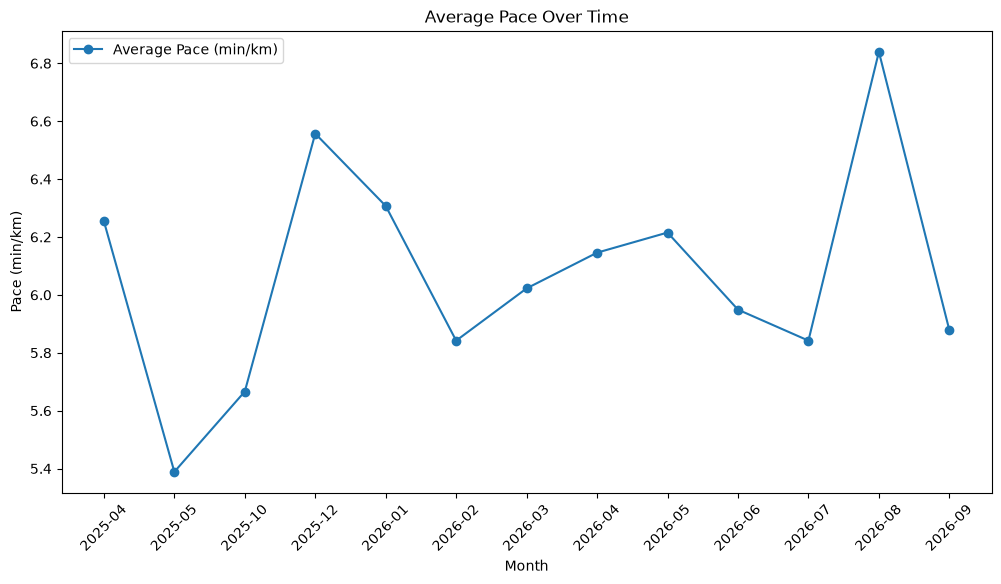

In [ ]:
# Create a larger chart canvas and plot average monthly pace over time
mp.figure(figsize=(12,6));
mp.plot(
monthly_summary.index.astype(str),
monthly_summary["average_pace"],
marker="o",
label="Average Pace (min/km)"
);

mp.title("Average Pace Over Time");
mp.xlabel("Month");
mp.ylabel("Pace (min/km)");
mp.xticks(rotation=45);
mp.legend();

mp.show()

In [ ]:
# Calculate total distance run each month   
monthly_distance = runs.groupby("Month")["Distance"].sum();
monthly_distance

Month
2025-04    10.42
2025-05     6.45
2025-10     6.68
2025-12    30.42
2026-01    15.45
2026-02    16.06
2026-03    73.22
2026-04    50.40
2026-05    38.29
2026-06    43.47
2026-07    35.34
2026-08    64.69
2026-09    42.40
Freq: M, Name: Distance, dtype: float64

In [ ]:
# Rebuild summary table with distance included
monthly_summary = pd.DataFrame({
"average_pace": monthly_pace,
"run_count": monthly_runs,
"total_distance": monthly_distance
});

monthly_summary

,average_pace,run_count,total_distance
Month,,,
2025-04,6.254360,2,10.42
2025-05,5.388655,2,6.45
2025-10,5.666168,1,6.68
2025-12,6.557067,6,30.42
2026-01,6.307197,3,15.45
2026-02,5.841857,3,16.06
2026-03,6.022388,13,73.22
2026-04,6.145767,6,50.40
2026-05,6.215273,6,38.29


In [34]:
monthly_summary.head()

,average_pace,run_count,total_distance
Month,,,
2025-04,6.254360,2,10.42
2025-05,5.388655,2,6.45
2025-10,5.666168,1,6.68
2025-12,6.557067,6,30.42
2026-01,6.307197,3,15.45


In [35]:
monthly_summary.describe()

,average_pace,run_count,total_distance
count,13.000000,13.000000,13.000000
mean,6.069794,5.153846,33.330000
std,0.379854,3.158221,21.725203
min,5.388655,1.000000,6.450000
25%,5.841923,3.000000,15.450000
50%,6.022388,6.000000,35.340000
75%,6.254360,6.000000,43.470000
max,6.839465,13.000000,73.220000


In [ ]:
# Find the month with the highest run count
monthly_summary["run_count"].idxmax()

Period('2026-03', 'M')

In [ ]:
# Find the month with the highest distance
monthly_summary["total_distance"].idxmax()

Period('2026-03', 'M')

In [ ]:
# View all metrics for the busiest month
monthly_summary.loc[monthly_summary["run_count"].idxmax()]

average_pace       6.022388
run_count         13.000000
total_distance    73.220000
Name: 2026-03, dtype: float64

In [ ]:
# Find the month with the fastest average pace
monthly_summary["average_pace"].idxmin()

Period('2025-05', 'M')

In [ ]:
# Display metrics for fastest month
monthly_summary.loc[monthly_summary["average_pace"].idxmin()]

average_pace      5.388655
run_count         2.000000
total_distance    6.450000
Name: 2025-05, dtype: float64

In [ ]:
# Find the month with the slowest average pace
monthly_summary["average_pace"].idxmax()

Period('2026-08', 'M')

In [ ]:
# Display metrics for slowest month
monthly_summary.loc[monthly_summary["average_pace"].idxmax()]

average_pace       6.839465
run_count          8.000000
total_distance    64.690000
Name: 2026-08, dtype: float64

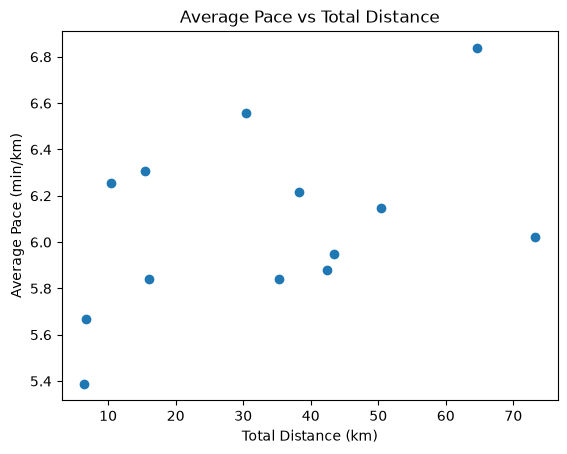

In [ ]:
# Create a scatter plot to investigate the relationship between monthly distance and monthly pace
mp.scatter(
    x=monthly_summary["total_distance"],
    y=monthly_summary["average_pace"],
    );

mp.xlabel("Total Distance (km)");
mp.ylabel("Average Pace (min/km)");
mp.title("Average Pace vs Total Distance");
mp.show();


In [ ]:
# Calculate the correlation between distance and pace
# Positive correlation means higher distance tends to coincide with slower pace
monthly_summary["total_distance"].corr(monthly_summary["average_pace"])

np.float64(0.44385614866267176)

In [ ]:
# Calculate overall average monthly pace
monthly_summary["average_pace"].mean()

np.float64(6.0697936306014135)

In [ ]:
# Calculate how much slower the slowest month was compared with the overall average
monthly_summary["average_pace"].max() - monthly_summary["average_pace"].mean()

np.float64(0.7696710831028417)

In [ ]:
# View all available running columns
[c for c in runs.columns]

['Activity ID',
 'Activity Date',
 'Activity Name',
 'Activity Type',
 'Activity Description',
 'Elapsed Time',
 'Distance',
 'Max Heart Rate',
 'Relative Effort',
 'Commute',
 'Activity Private Note',
 'Activity Gear',
 'Filename',
 'Athlete Weight',
 'Bike Weight',
 'Elapsed Time.1',
 'Moving Time',
 'Distance.1',
 'Max Speed',
 'Average Speed',
 'Elevation Gain',
 'Elevation Loss',
 'Elevation Low',
 'Elevation High',
 'Max Grade',
 'Average Grade',
 'Average Positive Grade',
 'Average Negative Grade',
 'Max Cadence',
 'Average Cadence',
 'Max Heart Rate.1',
 'Average Heart Rate',
 'Max Watts',
 'Average Watts',
 'Calories',
 'Max Temperature',
 'Average Temperature',
 'Relative Effort.1',
 'Total Work',
 'Number of Runs',
 'Uphill Time',
 'Downhill Time',
 'Other Time',
 'Perceived Exertion',
 'Type',
 'Start Time',
 'Weighted Average Power',
 'Power Count',
 'Prefer Perceived Exertion',
 'Perceived Relative Effort',
 'Commute.1',
 'Total Weight Lifted',
 'From Upload',
 'Grade Adj

In [48]:
runs["Average Heart Rate"].describe()

count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: Average Heart Rate, dtype: float64